# 02 · Preprocesamiento y variables por corte k
TA Aprendizaje de Máquina, grupo 5. Entregable 2.

**Objetivo.** Limpiar Times y Monitoring, unirlos y construir el dataset vuelta × corte k (k ∈ {4, 6, 9, 12, 15}) sin información posterior al corte. Al tratarse de datos reales, cada decisión de limpieza se contrasta con evidencia: la regla de valores extremos con la distribución observada, la limpieza del GPS con la velocidad calculada a partir de las coordenadas, y las variantes de preprocesamiento (interpolación, limpieza del GPS, selección de variables, recorte del objetivo) con el MAE de validación.

**Entradas:** `data/raw/Times.csv`, `data/raw/Monitoring.csv`.
**Salidas:** `data/processed/corte_k{k}.pkl` (con regla de 60 min) y `corte_k{k}_sin_regla.pkl`; tablas y figuras con prefijo `02_`.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor

RAIZ = Path("..")
sys.path.insert(0, str(RAIZ.resolve()))
from src.datos import (COL_DIF, PUNTOS, UMBRAL_EXTREMO, LAP_FUERA_DE_OPERACION, VEL_MAX_GPS, _haversine_km,
                       aplicar_regla_extremos, cargar_monitoring, cargar_times, limpiar_saltos_gps,
                       velocidad_calculada)
from src.variables import (CORTES, GRUPOS, NOMBRE_GRUPO, columnas_detalle, columnas_modelo, construir_corte,
                           indexar_gps, pasadas_por_punto)
from src.particion import asignar_particion
from src.modelos import pipeline, validar_y_probar
from src import graficos

SEMILLA = 42
DIR_RAW = RAIZ / "data" / "raw"
DIR_PROC = RAIZ / "data" / "processed"
DIR_FIG = RAIZ / "results" / "figures"
DIR_TAB = RAIZ / "results" / "tables"
for d in (DIR_PROC, DIR_FIG, DIR_TAB):
    d.mkdir(parents=True, exist_ok=True)
graficos.estilo()
pd.set_option("display.max_columns", 40)

## 1. Carga
Times se convierte a una fila por vuelta con 18 columnas de hora programada (`prog_j`), hora real (`real_j`, NaN si `00:00:00`) y diferencia (`dif_j`, NaN si `-`). En Monitoring se descartan los puntos con `lap` = 0 (fuera de operación) y las filas repetidas sin contar el `id`.

In [2]:
vueltas = cargar_times(DIR_RAW / "Times.csv")
mon_bruto = pd.read_csv(DIR_RAW / "Monitoring.csv", usecols=["date", "time", "lap", "latitude", "longitude",
                                                            "speed", "bearing", "vehicle_id_id"])
gps = cargar_monitoring(DIR_RAW / "Monitoring.csv")

resumen_carga = pd.Series({
    "Times: vueltas": len(vueltas),
    "Times: vehículos": vueltas["vehiculo"].nunique(),
    "Times: días": vueltas["fecha"].nunique(),
    "Monitoring: filas": len(mon_bruto),
    "Monitoring: lap = 0": int((mon_bruto["lap"] == LAP_FUERA_DE_OPERACION).sum()),
    "Monitoring: repetidas sin id": int(mon_bruto.duplicated().sum()),
    "Monitoring: filas usadas": len(gps),
})
del mon_bruto
resumen_carga

Times: vueltas                     4707
Times: vehículos                     45
Times: días                          27
Monitoring: filas               1630431
Monitoring: lap = 0               47921
Monitoring: repetidas sin id       6690
Monitoring: filas usadas        1575820
dtype: int64

## 2. Análisis exploratorio
Faltantes y valores extremos por punto de control, distribución del objetivo (punto 18) y relación del atraso de cada punto con el del punto 18.

In [3]:
dif = vueltas[COL_DIF].to_numpy()
extremo = np.abs(dif) > UMBRAL_EXTREMO
dif_limpio = np.where(extremo, np.nan, dif)
y18 = dif_limpio[:, PUNTOS - 1]

por_punto = pd.DataFrame({
    "punto": range(1, PUNTOS + 1),
    "pct_faltante": 100 * np.isnan(dif).mean(axis=0),
    "n_extremos": extremo.sum(axis=0),
    "media": np.nanmean(dif_limpio, axis=0),
    "desv_est": np.nanstd(dif_limpio, axis=0),
    "corr_con_18": [pd.Series(dif_limpio[:, j]).corr(pd.Series(y18)) for j in range(PUNTOS)],
}).round(3)
por_punto.to_csv(DIR_TAB / "02_eda_por_punto.csv", index=False)
por_punto

,punto,pct_faltante,n_extremos,media,desv_est,corr_con_18
0,1,6.650,1,-0.680,1.840,-0.070
1,2,5.821,2,-1.346,1.856,-0.077
2,3,12.152,0,-1.032,1.218,0.034
3,4,6.034,0,-0.118,1.514,0.392
4,5,6.650,0,-0.278,2.425,0.539
5,6,6.926,0,0.938,4.133,0.722
6,7,6.607,0,0.323,4.083,0.723
7,8,6.289,0,1.225,4.299,0.729
8,9,6.522,0,0.760,4.110,0.720
9,10,6.628,1,0.270,4.186,0.761


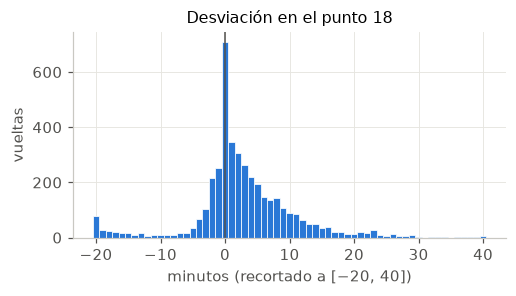

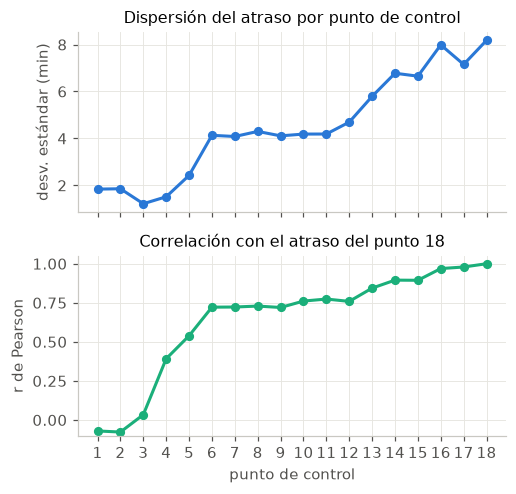

Punto 18 sin extremos: n=4146, mediana=2.0, media=2.72, p05=-13, p95=16, p99=26


In [4]:
v = y18[~np.isnan(y18)]
fig, ax = plt.subplots(figsize=(4.8, 2.8))
ax.hist(np.clip(v, -20, 40), bins=np.arange(-20.5, 41.5, 1), color=graficos.PALETA[0], edgecolor="white", linewidth=0.5)
ax.axvline(0, color=graficos.TEXTO_SEC, linewidth=1)
ax.set(title="Desviación en el punto 18", xlabel="minutos (recortado a [−20, 40])", ylabel="vueltas")
graficos.guardar(fig, DIR_FIG / "02_eda_punto18.png")

fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.6), sharex=True)
ejes[0].plot(por_punto["punto"], por_punto["desv_est"], marker="o", color=graficos.PALETA[0])
ejes[0].set(title="Dispersión del atraso por punto de control", ylabel="desv. estándar (min)")
ejes[1].plot(por_punto["punto"], por_punto["corr_con_18"], marker="o", color=graficos.PALETA[2])
ejes[1].set(title="Correlación con el atraso del punto 18", xlabel="punto de control", ylabel="r de Pearson",
            ylim=(-0.1, 1.05), xticks=range(1, PUNTOS + 1))
graficos.guardar(fig, DIR_FIG / "02_eda_por_punto.png")
print(f"Punto 18 sin extremos: n={len(v)}, mediana={np.median(v):.1f}, media={v.mean():.2f}, "
      f"p05={np.percentile(v, 5):.0f}, p95={np.percentile(v, 95):.0f}, p99={np.percentile(v, 99):.0f}")

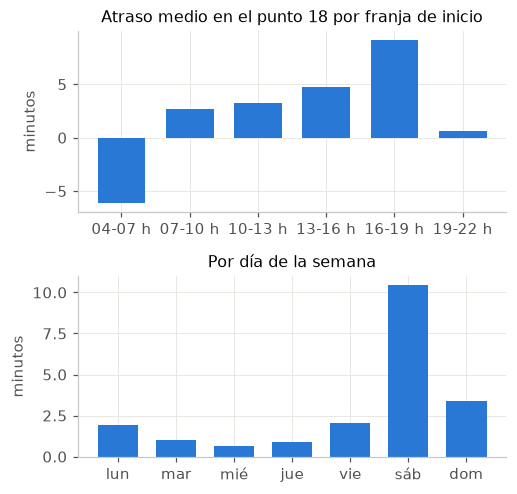

count   mean  median
franja 04-07 h    739  -6.16    -2.0
       07-10 h    875   2.66     1.0
       10-13 h    856   3.23     1.0
       13-16 h    840   4.72     3.0
       16-19 h    727   9.19     8.0
       19-22 h    109   0.61    -1.0
dia    lun        613   1.94     2.0
       mar        657   1.00     1.0
       mié        676   0.66     0.0
       jue        670   0.90     1.0
       vie        663   2.05     2.0
       sáb        576  10.46    11.0
       dom        291   3.36     1.0

In [5]:
eda = pd.DataFrame({
    "y": y18,
    "dia": vueltas["fecha"].dt.dayofweek,
    "hora": vueltas["prog_1"] / 60,
})
eda["franja"] = pd.cut(eda["hora"], bins=[4, 7, 10, 13, 16, 19, 22], right=False,
                       labels=["04-07 h", "07-10 h", "10-13 h", "13-16 h", "16-19 h", "19-22 h"]).astype(str)
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
eda["dia_nombre"] = eda["dia"].map(dict(enumerate(DIAS)))
por_franja = eda.groupby("franja")["y"].agg(["count", "mean", "median"]).round(2)
por_dia = eda.groupby("dia")["y"].agg(["count", "mean", "median"]).round(2).set_index(pd.Index(DIAS, name="dia"))
pd.concat({"franja": por_franja, "dia": por_dia}).to_csv(DIR_TAB / "02_eda_franja_dia.csv")

fig, ejes = plt.subplots(2, 1, figsize=(4.8, 4.6))
ejes[0].bar(por_franja.index, por_franja["mean"], color=graficos.PALETA[0], width=0.7)
ejes[0].set(title="Atraso medio en el punto 18 por franja de inicio", ylabel="minutos")
ejes[1].bar(por_dia.index, por_dia["mean"], color=graficos.PALETA[0], width=0.7)
ejes[1].set(title="Por día de la semana", ylabel="minutos")
graficos.guardar(fig, DIR_FIG / "02_eda_franja_dia.png")
pd.concat({"franja": por_franja, "dia": por_dia})

## 3. Filtros
El objetivo es `difference_time` del punto 18; se excluyen las vueltas sin ese valor. Con la regla provisional, todo punto con |valor| > 60 min se trata como error de registro: si es el punto 18, la vuelta sale del dataset; si es un punto intermedio, pasa a faltante.

In [6]:
sin_18 = vueltas["dif_18"].isna()
y_extremo = vueltas["dif_18"].abs() > UMBRAL_EXTREMO
filtros = pd.Series({
    "Vueltas en Times": len(vueltas),
    "Sin punto 18 válido": int(sin_18.sum()),
    "Con punto 18 válido (sin regla)": int((~sin_18).sum()),
    "|punto 18| > 60 min": int(y_extremo.sum()),
    "Con regla de 60 min": int((~sin_18 & ~y_extremo).sum()),
    "Puntos intermedios > 60 min en vueltas que quedan": int(extremo[(~sin_18 & ~y_extremo).to_numpy(), :PUNTOS - 1].sum()),
    "Horario no creciente (se mantienen con indicador)": int((np.diff(vueltas.filter(like="prog_").to_numpy(), axis=1) < 0).any(axis=1).sum()),
}, name="vueltas")
filtros.to_csv(DIR_TAB / "02_filtros.csv")
filtros

Vueltas en Times                                     4707
Sin punto 18 válido                                   515
Con punto 18 válido (sin regla)                      4192
|punto 18| > 60 min                                    46
Con regla de 60 min                                  4146
Puntos intermedios > 60 min en vueltas que quedan       1
Horario no creciente (se mantienen con indicador)     148
Name: vueltas, dtype: int64

### 3.1 Contraste de la regla de 60 min
La regla fija se compara con la distribución de |difference_time| en todos los puntos y con dos criterios robustos alternativos: la cerca de Tukey (Q1 − 3·IQR, Q3 + 3·IQR) sobre el punto 18 y una puntuación z robusta por punto (mediana y MAD). También se buscan picos aislados: un punto que sube y baja más de 5 min respecto a sus dos vecinos.

In [7]:
a = np.abs(dif[~np.isnan(dif)])
tramos = pd.cut(a, [0, 20, 30, 40, 50, 60, 90, 120, np.inf], right=True,
                labels=["0–20", "20–30", "30–40", "40–50", "50–60", "60–90", "90–120", "> 120"])
dist_abs = tramos.value_counts().sort_index().rename("puntos").to_frame()
dist_abs["pct"] = (100 * dist_abs["puntos"] / len(a)).round(3)

y_bruto = vueltas["dif_18"].dropna()
q1, q3 = y_bruto.quantile([0.25, 0.75])
iqr = q3 - q1
med = np.nanmedian(dif, axis=0)
mad = 1.4826 * np.nanmedian(np.abs(dif - med), axis=0)
z = np.abs(dif - med) / np.where(mad > 0, mad, 1)
saltos = np.diff(np.where(extremo, np.nan, dif), axis=1)
picos = (np.abs(saltos[:, :-1]) > 5) & (np.abs(saltos[:, 1:]) > 5) & (np.sign(saltos[:, :-1]) != np.sign(saltos[:, 1:]))
contraste = pd.Series({
    "Puntos con |valor| > 60 min (regla)": int(extremo.sum()),
    "Puntos con |valor| entre 40 y 60 min": int(((a > 40) & (a <= 60)).sum()),
    "Puntos con |valor| > 120 min": int((a > 120).sum()),
    f"Punto 18 fuera de la cerca de Tukey [{q1 - 3 * iqr:.0f}, {q3 + 3 * iqr:.0f}]": int(((y_bruto < q1 - 3 * iqr) | (y_bruto > q3 + 3 * iqr)).sum()),
    "Punto 18 con |valor| > 60 min": int((y_bruto.abs() > UMBRAL_EXTREMO).sum()),
    "Puntos con z robusta > 10": int(np.nansum(z > 10)),
    "Picos aislados (> 5 min de ida y vuelta)": int(picos.sum()),
}, name="conteo")
dist_abs.to_csv(DIR_TAB / "02_distribucion_extremos.csv")
contraste.to_csv(DIR_TAB / "02_contraste_regla.csv")
display(dist_abs)
contraste

,puntos,pct
0–20,51830,67.329
20–30,623,0.809
30–40,58,0.075
40–50,17,0.022
50–60,7,0.009
60–90,7,0.009
90–120,11,0.014
> 120,138,0.179


Puntos con |valor| > 60 min (regla)              156
Puntos con |valor| entre 40 y 60 min              24
Puntos con |valor| > 120 min                     138
Punto 18 fuera de la cerca de Tukey [-18, 24]    210
Punto 18 con |valor| > 60 min                     46
Puntos con z robusta > 10                        760
Picos aislados (> 5 min de ida y vuelta)           0
Name: conteo, dtype: int64

### 3.2 Limpieza del GPS y verificación de unidades (V9 y V17)
Con las coordenadas se calcula la velocidad entre puntos consecutivos del mismo vehículo y día. Se usa para (1) confirmar la unidad de `speed`, (2) eliminar puntos aislados fuera de lugar, a los que se llega y de los que se sale a más de 144 km/h, y (3) medir cuánto se aleja el primer punto de cada vuelta del inicio típico de la ruta.

In [8]:
g_vel = velocidad_calculada(gps)
ok = g_vel["dt_s"].between(5, 60) & g_vel["vel_calc"].between(5, 80) & (g_vel["speed"] > 0)
cociente = (g_vel["speed"] / g_vel["vel_calc"])[ok]
gps_limpio, n_picos = limpiar_saltos_gps(gps)
primeros = gps_limpio.sort_values("t").groupby(["vehiculo", "fecha", "lap"])[["lat", "lon"]].first()
dist_inicio = _haversine_km(primeros["lat"], primeros["lon"], primeros["lat"].median(), primeros["lon"].median())
limpieza_gps = pd.Series({
    "Puntos GPS en operación": len(gps),
    "Pares con velocidad calculada > 144 km/h": int((g_vel["vel_calc"] > VEL_MAX_GPS).sum()),
    "Puntos aislados eliminados": n_picos,
    "Puntos GPS tras la limpieza": len(gps_limpio),
    "Cociente mediano speed / velocidad calculada": round(float(cociente.median()), 3),
    "Correlación speed vs velocidad calculada": round(float(np.corrcoef(g_vel.loc[ok, "speed"], g_vel.loc[ok, "vel_calc"])[0, 1]), 3),
    "Vueltas con GPS": len(primeros),
    "Vueltas que empiezan a más de 1 km del inicio típico (%)": round(float(100 * (dist_inicio > 1).mean()), 2),
}, name="valor")
limpieza_gps.to_csv(DIR_TAB / "02_limpieza_gps.csv")
del g_vel
limpieza_gps

Puntos GPS en operación                                     1575820.000
Pares con velocidad calculada > 144 km/h                       2879.000
Puntos aislados eliminados                                     1853.000
Puntos GPS tras la limpieza                                 1573967.000
Cociente mediano speed / velocidad calculada                      1.072
Correlación speed vs velocidad calculada                          0.646
Vueltas con GPS                                                5381.000
Vueltas que empiezan a más de 1 km del inicio típico (%)          7.410
Name: valor, dtype: float64

El cociente mediano entre `speed` y la velocidad calculada es cercano a 1, así que `speed` está en km/h (V9 queda cerrada). Los puntos aislados se eliminan antes de calcular las variables GPS. Para V17 se agrega la variable `gps_dist_inicio` (km del primer punto de la vuelta al inicio típico), que marca las vueltas parciales o con GPS fuera de ruta en lugar de descartarlas.

### 3.3 Flujo de la limpieza
Registros que quedan tras cada paso. Las vueltas sin punto 18 no tienen respuesta que aprender; la regla de 60 min quita los errores de registro contrastados en 3.1.

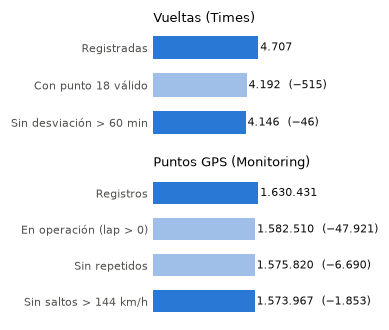

In [9]:
# Flujo de la limpieza: cuántos registros quedan tras cada paso (vueltas de Times y puntos de Monitoring).
pasos_vueltas = [
    ("Registradas", filtros["Vueltas en Times"]),
    ("Con punto 18 válido", filtros["Con punto 18 válido (sin regla)"]),
    ("Sin desviación > 60 min", filtros["Con regla de 60 min"]),
]
pasos_gps = [
    ("Registros", resumen_carga["Monitoring: filas"]),
    ("En operación (lap > 0)", resumen_carga["Monitoring: filas"] - resumen_carga["Monitoring: lap = 0"]),
    ("Sin repetidos", limpieza_gps["Puntos GPS en operación"]),
    ("Sin saltos > 144 km/h", limpieza_gps["Puntos GPS tras la limpieza"]),
]


def miles(n):
    return f"{int(n):,}".replace(",", ".")


fig, ejes = plt.subplots(2, 1, figsize=(3.5, 3.1), gridspec_kw={"height_ratios": [3, 4]})
for ax, pasos, titulo in ((ejes[0], pasos_vueltas, "Vueltas (Times)"), (ejes[1], pasos_gps, "Puntos GPS (Monitoring)")):
    nombres = [n for n, _ in pasos][::-1]
    valores = [v for _, v in pasos][::-1]
    colores = [graficos.PALETA[0] if i in (0, len(pasos) - 1) else "#9fbfe8" for i in range(len(pasos))][::-1]
    ax.barh(nombres, valores, color=colores, height=0.62)
    for j, (n, v) in enumerate(zip(nombres, valores)):
        previo = valores[j + 1] if j + 1 < len(valores) else None
        etiqueta = miles(v) + (f"  (−{miles(previo - v)})" if previo is not None else "")
        ax.text(v * 1.02, j, etiqueta, va="center", fontsize=7, color=graficos.TEXTO)
    ax.set(xlim=(0, max(valores) * 2.0), xticks=[])
    ax.set_title(titulo, fontsize=8.5, loc="left")
    ax.grid(False)
    ax.spines[["bottom", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0, labelsize=7.5)
graficos.guardar(fig, DIR_FIG / "02_flujo_limpieza.png")

## 4. Evaluación de variantes de preprocesamiento
Cada variante se compara con **Gradient Boosting con hiperparámetros fijos** (200 árboles, tasa 0,05, profundidad 3, hoja mínima 10) y el **MAE medio de los 4 pliegues de validación**; el conjunto de prueba no se usa para decidir.

- **V0 base:** regla de 60 min, faltantes como NaN + indicador (imputación por mediana dentro del pipeline).
- **V1 + interpolación:** los faltantes internos de los puntos 1..k se interpolan linealmente entre los puntos observados de la misma vuelta (no se extrapola: no hay fuga).
- **V2 + GPS limpio:** sin puntos aislados y con `gps_dist_inicio`.
- **V3 + selección:** se quitan los indicadores de faltante y los tramos programados de cada punto (quedan resumidos en `atr_n_faltantes`, `atr_dist_ultimo` y `hor_restante`).
- **V4 + recorte del objetivo:** el atraso final de entrenamiento se recorta a sus percentiles 1 y 99 (solo para ajustar; se evalúa contra el valor real).

In [10]:
base = aplicar_regla_extremos(vueltas)
pasadas = pasadas_por_punto(base)
indice_bruto, indice_limpio = indexar_gps(gps), indexar_gps(gps_limpio)
gb_fijo = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=3, min_samples_leaf=10,
                                    subsample=0.8, random_state=SEMILLA)


def sin_distancia(x):
    return [c for c in columnas_modelo(x) if c != "gps_dist_inicio"]


def mae_val_recorte(cols, tr):
    errores = []
    for f in range(4):
        ent, val = tr[tr["bloque"] < f], tr[tr["bloque"] == f]
        lo, hi = np.quantile(ent["y"], [0.01, 0.99])
        m = pipeline(cols, gb_fijo).fit(ent[cols], ent["y"].clip(lo, hi))
        errores.append(np.mean(np.abs(m.predict(val[cols]) - val["y"])))
    return float(np.mean(errores))


inicio = time.time()
filas_var = []
for k in CORTES:
    x_bruto = asignar_particion(construir_corte(base, k, indice_bruto, pasadas))
    x_interp = asignar_particion(construir_corte(base, k, indice_bruto, pasadas, interpolar=True))
    x_limpio = asignar_particion(construir_corte(base, k, indice_limpio, pasadas, interpolar=True))
    seleccion = [c for c in columnas_modelo(x_limpio) if c not in columnas_detalle(x_limpio)]
    casos = {"V0 base": (x_bruto, sin_distancia(x_bruto)), "V1 + interpolación": (x_interp, sin_distancia(x_interp)),
             "V2 + GPS limpio": (x_limpio, columnas_modelo(x_limpio)), "V3 + selección": (x_limpio, seleccion)}
    for nombre, (x, cols) in casos.items():
        tr = x[x["conjunto"] == "train"].reset_index(drop=True)
        te = x[x["conjunto"] == "test"].reset_index(drop=True)
        mae_val, _ = validar_y_probar(pipeline(cols, gb_fijo), cols, tr, te)
        filas_var.append({"k": k, "variante": nombre, "variables": len(cols), "MAE_val": mae_val})
    tr = x_limpio[x_limpio["conjunto"] == "train"].reset_index(drop=True)
    filas_var.append({"k": k, "variante": "V4 + recorte del objetivo", "variables": len(seleccion),
                      "MAE_val": mae_val_recorte(seleccion, tr)})
print(f"{(time.time() - inicio) / 60:.1f} min")
variantes = pd.DataFrame(filas_var)
variantes.to_csv(DIR_TAB / "02_variantes_preprocesamiento.csv", index=False, float_format="%.6f")
tabla_var = variantes.pivot(index="variante", columns="k", values="MAE_val")
tabla_var["media"] = tabla_var.mean(axis=1)
tabla_var.join(variantes.pivot(index="variante", columns="k", values="variables").add_prefix("n_k")).round(3)

2.0 min


k,4,6,9,12,15,media,n_k4,n_k6,n_k9,n_k12,n_k15
variante,,,,,,,,,,,
V0 base,3.100,3.040,2.974,2.793,2.382,2.858,47,49,52,55,58
V1 + interpolación,3.098,3.032,2.985,2.791,2.378,2.857,47,49,52,55,58
V2 + GPS limpio,3.106,3.043,2.986,2.790,2.379,2.861,48,50,53,56,59
V3 + selección,3.098,3.046,2.986,2.794,2.379,2.861,30,32,35,38,41
V4 + recorte del objetivo,3.084,3.057,2.992,2.833,2.430,2.879,30,32,35,38,41


**Elección.** Las variantes V0 a V3 quedan dentro de ±0,01 min de MAE medio de validación (2,857 a 2,861): con este volumen de datos, Gradient Boosting ya maneja bien los faltantes y las variables redundantes. Se adopta **V3** (interpolación, GPS limpio y selección) porque da el mismo error con un 30 a 42 % menos de variables (35 en lugar de 52 en k = 9), datos más limpios y modelos más fáciles de interpretar. El recorte del objetivo (V4) empeora la validación en k = 12 y 15 (+0,04 y +0,05 min) y se descarta: la cola de atrasos largos es información real, no ruido.

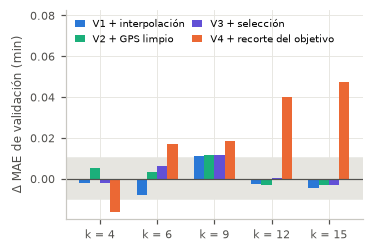

In [11]:
# Diferencia del MAE de validación de cada variante frente a la base V0 (negativo = mejor).
dif_var = variantes.pivot(index="k", columns="variante", values="MAE_val")
dif_var = dif_var.sub(dif_var["V0 base"], axis=0).drop(columns="V0 base")
fig, ax = plt.subplots(figsize=(3.5, 2.4))
ancho = 0.18
for i, nombre in enumerate(dif_var.columns):
    pos = np.arange(len(dif_var)) + (i - 1.5) * ancho
    ax.bar(pos, dif_var[nombre], width=ancho, label=nombre, color=graficos.PALETA[[0, 2, 6, 1][i]])
ax.axhline(0, color=graficos.TEXTO_SEC, linewidth=0.8)
ax.axhspan(-0.01, 0.01, color="#e6e5e0", zorder=0)
ax.set(xticks=np.arange(len(dif_var)), xticklabels=[f"k = {k}" for k in dif_var.index],
       ylabel="Δ MAE de validación (min)")
ax.legend(ncol=2, loc="upper left", fontsize=6.5, handlelength=1, columnspacing=0.8)
ax.set_ylim(top=dif_var.to_numpy().max() * 1.75)
ax.tick_params(labelsize=7.5)
ax.yaxis.label.set_size(8)
graficos.guardar(fig, DIR_FIG / "02_variantes_preprocesamiento.png")

## 5. Dataset final vuelta × corte k
Configuración elegida (V3: interpolación, GPS limpio y selección). El instante de predicción es la hora real de paso por el punto k (la programada si no se registró). Variables por grupo (prefijo):

- `hor_`: hora de inicio (seno, coseno y hora), día de la semana, minutos programados restantes y totales, indicador de horario no creciente.
- `atr_`: atraso en los puntos 1 a k (faltantes internos interpolados), último valor (entero y continuo), distancia al último registro, media de los últimos tres, máximo, mínimo, pendiente y número de faltantes originales.
- `ctx_`: vehículo, número de vuelta del día, atraso final de la vuelta anterior solo si terminó antes del corte, y atraso medio de otros vehículos en los 30 min previos al corte (con su número de registros).
- `gps_`: puntos GPS de la vuelta hasta el corte, velocidad media, proporción detenida (< 2 km/h), velocidad media de los últimos 10 min y distancia del inicio al inicio típico.

In [12]:
filas = []
for regla in (True, False):
    datos_base = base if regla else vueltas
    pas = pasadas if regla else pasadas_por_punto(vueltas)
    for k in CORTES:
        x = asignar_particion(construir_corte(datos_base, k, indice_limpio, pas, interpolar=True))
        x = x.drop(columns=columnas_detalle(x))
        sufijo = "" if regla else "_sin_regla"
        x.to_pickle(DIR_PROC / f"corte_k{k}{sufijo}.pkl")
        filas.append({"regla_60": regla, "k": k, "observaciones": len(x),
                      "train": int((x["conjunto"] == "train").sum()), "test": int((x["conjunto"] == "test").sum()),
                      "variables": len(columnas_modelo(x)),
                      **{f"vars_{g}": len(columnas_modelo(x, (g,))) for g in GRUPOS}})
filas_por_corte = pd.DataFrame(filas)
filas_por_corte.to_csv(DIR_TAB / "02_filas_por_corte.csv", index=False)
filas_por_corte

,regla_60,k,observaciones,train,test,variables,vars_hor,vars_atr,vars_ctx,vars_gps
0,True,4,4146,3085,1061,30,7,12,6,5
1,True,6,4146,3085,1061,32,7,14,6,5
2,True,9,4146,3085,1061,35,7,17,6,5
3,True,12,4146,3085,1061,38,7,20,6,5
4,True,15,4146,3085,1061,41,7,23,6,5
5,False,4,4192,3120,1072,30,7,12,6,5
6,False,6,4192,3120,1072,32,7,14,6,5
7,False,9,4192,3120,1072,35,7,17,6,5
8,False,12,4192,3120,1072,38,7,20,6,5
9,False,15,4192,3120,1072,41,7,23,6,5


### 5.1 Faltantes e imputación
Qué parte de las observaciones tiene datos faltantes y cómo se tratan. Si se eliminaran las vueltas con algún faltante, se perdería esa proporción de la muestra; por eso se imputan:
- **Atraso en los puntos 1 a k:** los faltantes *internos* (entre dos puntos registrados) se interpolan linealmente, porque el atraso evoluciona de forma continua (correlación 0,86 entre puntos consecutivos). Los *externos* (antes del primer o después del último registro) no se extrapolan: los completa la mediana del entrenamiento dentro del pipeline, y `atr_n_faltantes` y `atr_dist_ultimo` le indican al modelo que hubo hueco.
- **Contexto y GPS:** la vuelta anterior solo existe si terminó antes del corte y la flota solo si otro bus pasó en los 30 min previos; se imputan con la mediana del entrenamiento (`SimpleImputer`, ajustado en cada pliegue con sus filas de entrenamiento, sin fuga) y `ctx_previa_disp` marca la disponibilidad. Se usa la mediana y no la media porque el atraso tiene una cola larga de valores positivos.

In [13]:
filas_falt = []
for k in CORTES:
    x = pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl")
    obs = base.set_index("id").loc[x["id"], COL_DIF[:k]].to_numpy()
    falta = np.isnan(obs)
    cualquiera = falta.any(axis=1)
    primero = np.where(~falta, np.arange(k), k).min(axis=1)
    ultimo = np.where(~falta, np.arange(k), -1).max(axis=1)
    internos = falta & (np.arange(k) > primero[:, None]) & (np.arange(k) < ultimo[:, None])
    filas_falt.append({
        "k": k, "vueltas": len(x),
        "% vueltas con algún faltante en 1..k": round(100 * cualquiera.mean(), 1),
        "puntos faltantes en 1..k": int(falta.sum()),
        "% de esos faltantes interpolados (internos)": round(100 * internos.sum() / max(falta.sum(), 1), 1),
        "% sin vuelta anterior terminada": round(100 * x["ctx_previa_final"].isna().mean(), 1),
        "% sin otros buses en 30 min": round(100 * x["ctx_flota_30"].isna().mean(), 1),
        "% sin GPS hasta el corte": round(100 * x["gps_vel_media"].isna().mean(), 1),
    })
faltantes = pd.DataFrame(filas_falt)
faltantes.to_csv(DIR_TAB / "02_faltantes_imputacion.csv", index=False)
faltantes

,k,vueltas,% vueltas con algún faltante en 1..k,puntos faltantes en 1..k,% de esos faltantes interpolados (internos),% sin vuelta anterior terminada,% sin otros buses en 30 min,% sin GPS hasta el corte
0,4,4146,10.2,869,21.5,29.6,0.1,2.0
1,6,4146,10.8,1072,18.8,29.6,0.2,1.9
2,9,4146,11.1,1311,18.9,29.6,0.2,1.4
3,12,4146,11.5,1460,19.3,29.6,0.0,0.5
4,15,4146,12.2,1581,22.5,29.6,0.0,0.2


### 5.2 Experimentos adicionales de preprocesamiento
Con el dataset final (V3) y el mismo Gradient Boosting de hiperparámetros fijos de la sección 4, se prueban cambios que no se adoptaron: quitar las vueltas con horario no creciente o que empiezan a más de 1 km del inicio típico (en lugar de marcarlas), codificar el vehículo por su atraso medio en el entrenamiento (en lugar de one-hot) y agregar el atraso final de las vueltas de otros buses que terminaron en los 60 min previos al corte. Los filtros también quitan vueltas de los bloques de validación, así que su MAE no es del todo comparable.

In [14]:
fin = pd.DataFrame({"fecha": base["fecha"], "vehiculo": base["vehiculo"], "t18": base["real_18"],
                    "d18": base["dif_18"]}).dropna()
fin_por_fecha = {f: g for f, g in fin.groupby("fecha")}


def finales_recientes(x, k, ventana=60):
    """Atraso final medio de las vueltas de otros buses que terminaron en los `ventana` min previos al corte."""
    vv = base.set_index("id").loc[x["id"]]
    t_corte = np.where(np.isnan(vv[f"real_{k}"]), vv[f"prog_{k}"], vv[f"real_{k}"])
    salida = np.full(len(x), np.nan)
    for i, (f, veh, t) in enumerate(zip(x["fecha"].to_numpy(), x["vehiculo"].to_numpy(), t_corte)):
        g = fin_por_fecha.get(f)
        if g is not None:
            m = (g["t18"] < t) & (g["t18"] >= t - ventana) & (g["vehiculo"] != veh)
            salida[i] = g.loc[m, "d18"].mean() if m.any() else np.nan
    return salida


def mae_val_extra(x, cols, codificar_vehiculo=False):
    tr = x[x["conjunto"] == "train"].reset_index(drop=True)
    errores = []
    for f in range(4):
        ent, val = tr[tr["bloque"] < f].copy(), tr[tr["bloque"] == f].copy()
        if codificar_vehiculo:  # media del objetivo por vehículo, suavizada y calculada solo con el entrenamiento del pliegue
            g = ent.groupby("vehiculo")["y"].agg(["mean", "count"])
            media = ent["y"].mean()
            codigo = (g["mean"] * g["count"] + media * 20) / (g["count"] + 20)
            for d in (ent, val):
                d["ctx_veh_media"] = d["vehiculo"].map(codigo).fillna(media).to_numpy()
        m = pipeline(cols, gb_fijo).fit(ent[cols], ent["y"])
        errores.append(np.mean(np.abs(m.predict(val[cols]) - val["y"])))
    return float(np.mean(errores))


inicio = time.time()
filas_extra = []
for k in CORTES:
    x = pd.read_pickle(DIR_PROC / f"corte_k{k}.pkl")
    cols = columnas_modelo(x)
    x["ctx_finales_60"] = finales_recientes(x, k)
    sin_veh = [c for c in cols if c != "ctx_vehiculo"]
    casos = {
        "V3 (dataset final)": (x, cols, False),
        "Quitar vueltas con horario no creciente": (x[x["hor_no_creciente"] == 0], cols, False),
        "Quitar vueltas que empiezan a más de 1 km": (x[~(x["gps_dist_inicio"] > 1)], cols, False),
        "Vehículo codificado por su atraso medio": (x, sin_veh + ["ctx_veh_media"], True),
        "+ atraso final de vueltas recientes (60 min)": (x, cols + ["ctx_finales_60"], False),
    }
    for nombre, (d, c, cod) in casos.items():
        filas_extra.append({"k": k, "variante": nombre, "MAE_val": mae_val_extra(d, c, cod)})
print(f"{(time.time() - inicio) / 60:.1f} min")
extra = pd.DataFrame(filas_extra)
extra.to_csv(DIR_TAB / "02_experimentos_adicionales.csv", index=False, float_format="%.6f")
tabla_extra = extra.pivot(index="variante", columns="k", values="MAE_val")
tabla_extra = tabla_extra.sub(tabla_extra.loc["V3 (dataset final)"], axis=1)
tabla_extra["media"] = tabla_extra.mean(axis=1)
tabla_extra.round(3)

3.0 min


k,4,6,9,12,15,media
variante,,,,,,
+ atraso final de vueltas recientes (60 min),0.011,0.000,-0.003,-0.006,0.014,0.003
Quitar vueltas con horario no creciente,-0.016,-0.012,0.004,-0.030,0.006,-0.010
Quitar vueltas que empiezan a más de 1 km,-0.004,-0.005,0.000,-0.020,-0.022,-0.010
V3 (dataset final),0.000,0.000,0.000,0.000,0.000,0.000
Vehículo codificado por su atraso medio,0.013,-0.002,0.028,-0.003,-0.003,0.007


**Resultado.** Ninguno de estos cambios mejora el MAE de validación de forma consistente en los cinco cortes: las diferencias quedan en el orden de ±0,03 min, dentro del ruido de la validación. Se mantiene V3: las vueltas atípicas se conservan con su indicador y el vehículo con one-hot.

## 6. Partición temporal y pliegues
Entrenamiento: 6–25 ene (20 días). Prueba: 26 ene–1 feb (7 días), usada una sola vez. Pliegues de ventana creciente: los 8 primeros días siempre entrenan y cada pliegue valida un bloque de 3 días consecutivos con todos los días anteriores.

In [15]:
x9 = pd.read_pickle(DIR_PROC / "corte_k9.pkl")
tr = x9[x9["conjunto"] == "train"]
pl = []
for f in range(4):
    ent, val = tr[tr["bloque"] < f], tr[tr["bloque"] == f]
    pl.append({"pliegue": f + 1,
               "entrena": f"{ent['fecha'].min():%d/%m}–{ent['fecha'].max():%d/%m}", "n_entrena": len(ent),
               "valida": f"{val['fecha'].min():%d/%m}–{val['fecha'].max():%d/%m}", "n_valida": len(val)})
pliegues_tab = pd.DataFrame(pl)
pliegues_tab.to_csv(DIR_TAB / "02_pliegues.csv", index=False)
pliegues_tab

,pliegue,entrena,n_entrena,valida,n_valida
0,1,06/01–13/01,1216,14/01–16/01,498
1,2,06/01–16/01,1714,17/01–19/01,401
2,3,06/01–19/01,2115,20/01–22/01,472
3,4,06/01–22/01,2587,23/01–25/01,498


In [16]:
cols = columnas_modelo(x9)
variables_k9 = pd.DataFrame({
    "variable": cols,
    "grupo": [NOMBRE_GRUPO[c.split("_")[0]] for c in cols],
    "pct_faltante": [round(100 * x9[c].isna().mean(), 2) for c in cols],
})
variables_k9.to_csv(DIR_TAB / "02_variables_k9.csv", index=False)
variables_k9.groupby("grupo", sort=False).agg(n=("variable", "size"), pct_faltante_max=("pct_faltante", "max"))

,n,pct_faltante_max
grupo,,
Horario,7,0.00
Atraso observado,17,5.64
Vehículo y contexto,6,29.57
GPS,5,1.59


## 7. Conclusiones
- Times tiene 4.707 vueltas; 515 (10,9 %) no tienen punto 18 válido y 46 superan 60 min en el punto 18. Con la regla quedan 4.146 observaciones por corte (3.085 de entrenamiento y 1.061 de prueba); sin ella, 4.192.
- **Regla de 60 min contrastada:** solo 24 puntos están entre 40 y 60 min, mientras que 138 superan los 120 min (hasta −1052), un salto que delata errores de registro. La cerca de Tukey sacaría 210 vueltas con atrasos reales (fuera de [−18, 24] min) y la z robusta marca 760 puntos porque la MAD es casi nula al inicio de la vuelta; no hay picos aislados. La regla fija es la que separa errores de atrasos reales.
- **GPS:** de Monitoring se descartan 47.921 puntos fuera de operación y 6.690 filas repetidas, y luego 1.853 puntos aislados a los que se llega y de los que se sale a más de 144 km/h: quedan 1.573.967. El cociente mediano entre `speed` y la velocidad calculada es 1,07, así que `speed` está en km/h (V9 cerrada). El 7,4 % de las vueltas empieza a más de 1 km del inicio típico (V17); se marca con `gps_dist_inicio`.
- **Faltantes:** se imputan en lugar de eliminar vueltas (ver 5.1): los internos se interpolan y el resto lo completa la mediana del entrenamiento dentro del pipeline, con indicadores de disponibilidad.
- **Experimentos adicionales (5.2):** quitar vueltas atípicas, codificar el vehículo por su atraso medio o agregar el atraso final de vueltas recientes no mejora el MAE de validación de forma consistente.
- **Variantes:** interpolar, limpiar el GPS y seleccionar variables no cambia el MAE de validación (±0,01 min), pero reduce las variables de 47–58 a 30–41. Recortar el objetivo empeora. El dataset final usa la variante V3.
- Objetivo sin extremos: mediana +2 min, media +2,72, p05 −13 y p95 +16. Las vueltas que inician entre 4 y 7 h terminan adelantadas (−6,2 min de media); las de 16 a 19 h (+9,2) y los sábados (+10,5) son las más atrasadas.
- La correlación con el punto 18 es casi nula en los puntos 1–3, sube a 0,72 en el punto 6 y a 0,89 en el 14: el atraso observado aporta sobre todo desde k = 6.

In [17]:
import platform, sklearn, scipy, matplotlib
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

Python 3.14.2 | pandas 3.0.3 | numpy 2.5.0 | scikit-learn 1.9.0 | scipy 1.18.0 | matplotlib 3.11.0
